# JRT results: graded response model, model ladder and reliability

Display notebook for the manuscript. It fits nothing: it shows the CSV and figure
outputs of the R pipeline in `../R/` (`01_data_design.R` … `06_summary.R`, see
`../server/README.md` and `../AUDIT.md`) as labelled tables and figures,
so the manuscript can embed them. Re-execute it (seconds) after every pipeline run.
Objects whose source file does not exist yet show a placeholder line.

Numbers in the text come from these tables through the results-interpreter.

Raters with fewer than 15 ratings are excluded from the whole pipeline (decision
2026-10-22; see `results/data/excluded_raters.csv`). Short notes above each object say
what it shows; references are listed at the end.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import Markdown

key = pd.read_csv("../data/raw/rater_pseudonym_key.csv")
to_orig = dict(zip(key.rater_id, key.original_rater_id))
to_pseudo = {v: k for k, v in to_orig.items()}

RES = Path("..").resolve() / "results"

def _missing(path):
    return Markdown(f"_Not available yet: `results/{path}` (run the R pipeline)._")

def read_res(path):
    f = RES / path
    return pd.read_csv(f) if f.exists() else None

def show_table(path, fn=None, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    df = read_res(path)
    if df is None:
        return _missing(path)
    if fn is not None:
        df = fn(df)
    return Markdown(df.to_markdown(index=False, floatfmt=f".{digits}f"))

def show_png(path, width=8):
    f = RES / path
    if not f.exists():
        return _missing(path)
    img = mpimg.imread(f)
    fig, ax = plt.subplots(figsize=(width, width * img.shape[0] / img.shape[1]))
    ax.imshow(img)
    ax.axis("off")
    fig.tight_layout(pad=0)
    plt.show()

## 1. Data and design

**Design.** Size and coverage of the products × raters matrix that every model uses. The design is incomplete: each product is rated by a few raters only, and missing ratings are left out of the likelihood, not imputed. A connected design (one component) is required so that all raters and products lie on one scale (Eckes, 2015).

In [2]:
#| label: tbl-design-summary
#| tbl-cap: "Data basis shared by all models: ratings, products, raters, coverage of the product x rater matrix and connectivity of the design."
show_table("data/design_summary.csv", lambda d: d[d["quantity"] != "data_fingerprint"])

| quantity                                  | value             |
|:------------------------------------------|:------------------|
| n_ratings                                 | 7820              |
| n_products                                | 3668              |
| n_raters                                  | 19                |
| min_ratings_per_rater (exclusion cut-off) | 15                |
| raters_excluded                           | R20;R21;R22       |
| ratings_excluded                          | 24                |
| products_dropped                          | 1                 |
| n_categories                              | 7                 |
| scale                                     | 1-7               |
| internal_coding                           | rating - 1 (0-6)  |
| ratings_per_product_mean                  | 2.1319520174482   |
| ratings_per_product_median                | 2                 |
| ratings_per_product_min                   | 1                 |
| ratings_per_product_max                   | 10                |
| ratings_per_product_harmonic_mean         | 1.72615922960609  |
| products_with_1_rating                    | 897               |
| ratings_per_rater_min                     | 50                |
| ratings_per_rater_max                     | 1174              |
| matrix_fill                               | 0.112208000918326 |
| n_components                              | 1                 |
| rater_pairs_total                         | 171               |
| rater_pairs_without_overlap               | 17                |
| rater_pairs_overlap_median                | 13                |
| raters_with_category_gaps                 | 5                 |
| raters_with_internal_gap                  | 0                 |
| duplicate_pairs_resolved_in_00            | 12                |
| duplicate_pairs_conflicting               | 1                 |

In [3]:
#| label: tbl-excluded-raters
#| tbl-cap: "Raters excluded from all analyses because they gave fewer than 15 ratings."
show_table("data/excluded_raters.csv")

| rater_id   |   n_ratings | reason                |
|:-----------|------------:|:----------------------|
| R20        |          13 | fewer than 15 ratings |
| R21        |           9 | fewer than 15 ratings |
| R22        |           2 | fewer than 15 ratings |

**Category use.** How often each rater used each of the 7 categories. Raters who never use a category get fewer thresholds in mirt, because mirt only models the categories a rater actually used.

In [4]:
#| label: tbl-category-usage
#| tbl-cap: "Category use per rater (counts of ratings 1-7). Unused categories at the ends of the scale reduce the number of thresholds of a rater; an unused category inside the observed range (internal gap) makes that rater's thresholds incomparable with those of other raters."
show_table("data/category_usage.csv", lambda d: d[["rater_id"] + [c for c in d if c.startswith("cat_")] + ["n_ratings", "missing_categories", "internal_gap"]])

| rater_id   |   cat_1 |   cat_2 |   cat_3 |   cat_4 |   cat_5 |   cat_6 |   cat_7 |   n_ratings | missing_categories   | internal_gap   |
|:-----------|--------:|--------:|--------:|--------:|--------:|--------:|--------:|------------:|:---------------------|:---------------|
| R01        |     337 |     461 |     259 |      87 |      24 |       6 |       0 |        1174 | 7                    | False          |
| R02        |     241 |     179 |     124 |     126 |      91 |      67 |      45 |         873 | nan                  | False          |
| R03        |     161 |     182 |     185 |      82 |      88 |      22 |       0 |         720 | 7                    | False          |
| R04        |     164 |     164 |      90 |      69 |      92 |      36 |       5 |         620 | nan                  | False          |
| R05        |     159 |     190 |     102 |      90 |      50 |      30 |      12 |         633 | nan                  | False          |
| R06        |     301 |     113 |      57 |      34 |       9 |       6 |       0 |         520 | 7                    | False          |
| R07        |     183 |     152 |      96 |      61 |      36 |      17 |       2 |         547 | nan                  | False          |
| R08        |     101 |     127 |     106 |      91 |      60 |      30 |       7 |         522 | nan                  | False          |
| R09        |      63 |      62 |      72 |      60 |      66 |      55 |      22 |         400 | nan                  | False          |
| R10        |      25 |     156 |      76 |      64 |      47 |      13 |       2 |         383 | nan                  | False          |
| R11        |     127 |     118 |      51 |      31 |      32 |       9 |       1 |         369 | nan                  | False          |
| R12        |      11 |      48 |      90 |      77 |      27 |      10 |       1 |         264 | nan                  | False          |
| R13        |       4 |      35 |      68 |      91 |      44 |      11 |       1 |         254 | nan                  | False          |
| R14        |     105 |      66 |      40 |      31 |      10 |       5 |       2 |         259 | nan                  | False          |
| R15        |       7 |      22 |      11 |       9 |      13 |       9 |       2 |          73 | nan                  | False          |
| R16        |       4 |      14 |       9 |      14 |       5 |       3 |       3 |          52 | nan                  | False          |
| R17        |      25 |      10 |       9 |       4 |       4 |       0 |       0 |          52 | 6;7                  | False          |
| R18        |       1 |       8 |      14 |      12 |      16 |       4 |       0 |          55 | 7                    | False          |
| R19        |      10 |       6 |       8 |       6 |      10 |       6 |       4 |          50 | nan                  | False          |

## 2. Graded response model (central model)

**Central model.** Judge response theory treats raters as items and products as persons (Myszkowski & Storme, 2019). It is fitted here as a graded response model (Samejima, 1969) by marginal maximum likelihood in `mirt` (Chalmers, 2012). The table shows whether estimation converged and gives the information criteria.

In [5]:
#| label: tbl-grm-convergence
#| tbl-cap: "Estimation and convergence of the graded response model (marginal maximum likelihood, EM algorithm, fixed quadrature)."
show_table("grm/convergence.csv", lambda d: d[["method", "quadpts", "se_type", "tol", "converged", "iterations", "information_matrix_pd", "logLik", "npar", "AIC", "BIC", "SABIC", "n_products", "n_ratings"]])

| method   |   quadpts | se_type   |   tol | converged   |   iterations | information_matrix_pd   |     logLik |   npar |       AIC |       BIC |     SABIC |   n_products |   n_ratings |
|:---------|----------:|:----------|------:|:------------|-------------:|:------------------------|-----------:|-------:|----------:|----------:|----------:|-------------:|------------:|
| EM       |        61 | Oakes     | 0.000 | True        |          165 | True                    | -11733.227 |    127 | 23720.455 | 24508.795 | 24105.251 |         3668 |        7820 |

**Rater parameters.** a is the rater's discrimination: how sharply the ratings separate products of different creativity. b_k is the θ at which a rating at or above the k-th boundary becomes more likely than not; higher b means a stricter rater.

In [6]:
#| label: tbl-grm-rater-parameters
#| tbl-cap: "Rater parameters of the graded response model in IRT metric: discrimination a and thresholds b_k with standard errors; category_boundaries states which rating categories each threshold separates."
show_table("grm/rater_parameters.csv", lambda d: d[["rater_id", "n_ratings", "a", "a_se"] + [c for c in d if c[0] == "b" and c[1:].isdigit()] + ["category_boundaries", "thresholds_ordered"]])

| rater_id   |   n_ratings |     a |   a_se |     b1 |     b2 |     b3 |    b4 |      b5 |      b6 | category_boundaries     | thresholds_ordered   |
|:-----------|------------:|------:|-------:|-------:|-------:|-------:|------:|--------:|--------:|:------------------------|:---------------------|
| R01        |        1174 | 1.956 |  0.159 | -0.774 |  0.578 |  1.730 | 2.750 |   3.790 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R02        |         873 | 2.498 |  0.331 | -0.706 | -0.034 |  0.400 | 0.903 |   1.400 |   2.030 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R03        |         720 | 1.944 |  0.197 | -1.087 | -0.152 |  0.750 | 1.275 |   2.452 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R04        |         620 | 2.041 |  0.245 | -0.765 |  0.168 |  0.661 | 1.099 |   2.044 |   3.413 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R05        |         633 | 2.207 |  0.228 | -0.827 |  0.165 |  0.719 | 1.360 |   1.962 |   2.823 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R06        |         520 | 2.807 |  0.424 |  0.295 |  1.045 |  1.623 | 2.315 |   2.771 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R07        |         547 | 1.991 |  0.200 | -0.539 |  0.402 |  1.069 | 1.706 |   2.465 |   3.872 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R08        |         522 | 2.165 |  0.284 | -1.164 | -0.293 |  0.368 | 1.065 |   1.852 |   2.944 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R09        |         400 | 0.863 |  0.151 | -2.208 | -1.079 | -0.081 | 0.747 |   1.881 |   3.678 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R10        |         383 | 2.237 |  0.342 | -2.039 | -0.173 |  0.476 | 1.138 |   2.117 |   3.377 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R11        |         369 | 1.817 |  0.213 | -0.528 |  0.600 |  1.186 | 1.698 |   2.732 |   4.173 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R12        |         264 | 2.898 |  0.565 | -2.008 | -0.897 |  0.159 | 1.272 |   2.132 |   3.414 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R13        |         254 | 1.504 |  0.223 | -3.384 | -1.505 | -0.261 | 1.199 |   2.640 |   4.435 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R14        |         259 | 2.747 |  0.661 | -0.195 |  0.539 |  1.078 | 1.807 |   2.353 |   3.075 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R15        |          73 | 2.501 |  0.525 | -1.696 | -0.248 |  0.256 | 0.661 |   1.331 |   2.659 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R16        |          52 | 3.701 |  1.359 | -1.366 | -0.261 |  0.211 | 1.173 |   1.744 |   2.237 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R17        |          52 | 1.446 |  0.465 | -0.182 |  0.552 |  1.352 | 2.006 | nan     | nan     | 1|2;2|3;3|4;4|5         | True                 |
| R18        |          55 | 0.631 |  0.263 | -6.565 | -2.762 | -0.576 | 0.973 |   4.440 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R19        |          50 | 3.709 |  2.220 | -0.938 | -0.585 | -0.140 | 0.199 |   0.931 |   1.692 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |

**Category response functions.** The probability of each rating category as a function of θ, one panel per rater.

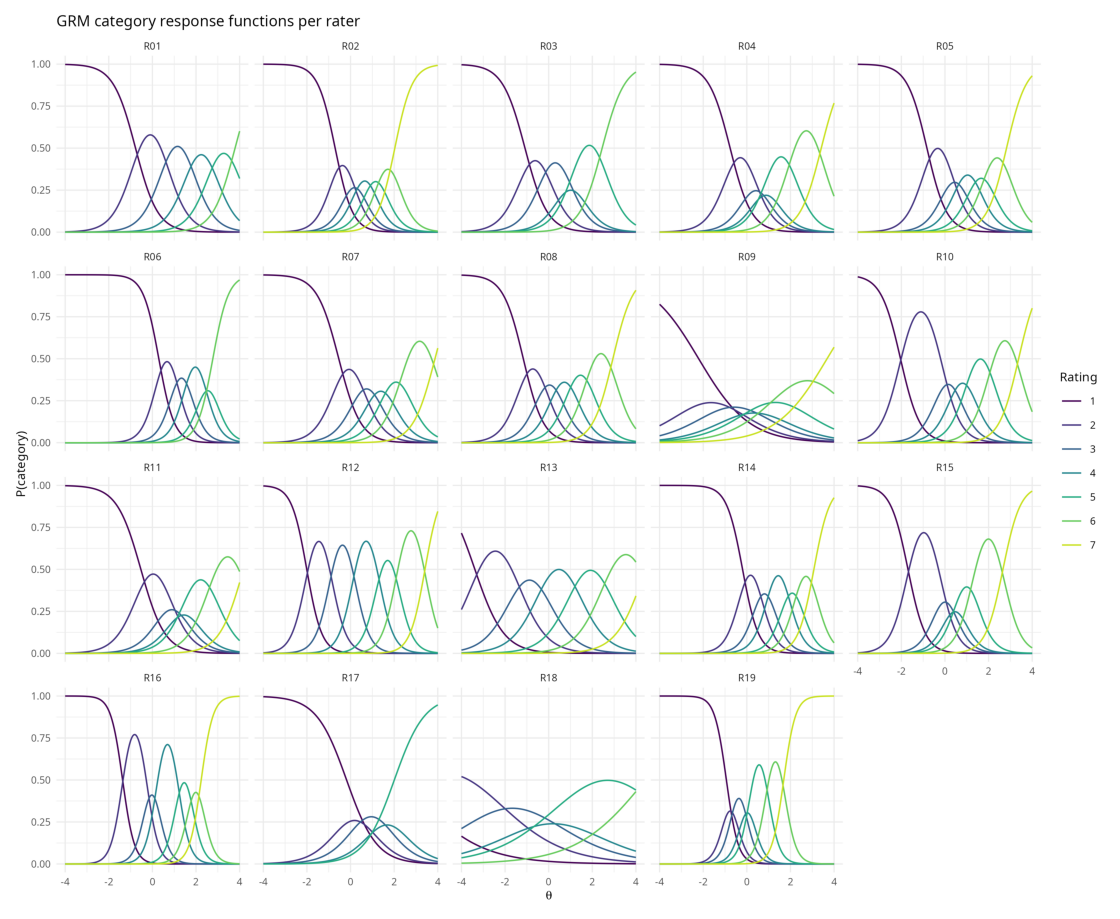

In [7]:
#| label: fig-grm-category-response-functions
#| fig-cap: "Category response functions of the graded response model for each rater."
show_png("grm/figures/grm_category_response_functions.png", width=11)

**Rater fit.** Infit and outfit are mean squares of the standardised residuals, with an expected value of 1 (Wright & Masters, 1982). With about 2 ratings per product, values below 1 are expected, because the score is estimated from the very ratings being checked. S-X² (Orlando & Thissen, 2000; Kang & Chen, 2008) needs complete data, so the missing ratings are imputed 20 times from the fitted model and S-X² is averaged. About 90% of the cells are imputed, which makes the test conservative.

In [8]:
#| label: tbl-grm-rater-fit
#| tbl-cap: "Rater fit in the graded response model: infit and outfit mean squares (observed ratings) and S-X2 pooled over multiple imputations of the missing ratings."
show_table("grm/rater_fit.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit", "S_X2", "df_S_X2", "p_S_X2", "n_imputations"]])

| rater_id   |   n_ratings |   infit |   outfit |    S_X2 |   df_S_X2 |   p_S_X2 |   n_imputations |
|:-----------|------------:|--------:|---------:|--------:|----------:|---------:|----------------:|
| R01        |        1174 |   0.680 |    0.650 | 218.569 |   213.550 |    0.392 |              20 |
| R02        |         873 |   0.450 |    0.423 | 289.502 |   300.850 |    0.671 |              20 |
| R03        |         720 |   0.699 |    0.687 | 277.954 |   280.450 |    0.531 |              20 |
| R04        |         620 |   0.588 |    0.554 | 280.793 |   290.200 |    0.643 |              20 |
| R05        |         633 |   0.617 |    0.576 | 291.511 |   293.850 |    0.528 |              20 |
| R06        |         520 |   0.604 |    0.469 | 193.853 |   190.100 |    0.411 |              20 |
| R07        |         547 |   0.724 |    0.645 | 282.598 |   285.850 |    0.543 |              20 |
| R08        |         522 |   0.585 |    0.571 | 282.277 |   285.000 |    0.534 |              20 |
| R09        |         400 |   0.871 |    0.870 | 440.411 |   433.550 |    0.400 |              20 |
| R10        |         383 |   0.624 |    0.603 | 247.751 |   250.600 |    0.539 |              20 |
| R11        |         369 |   0.829 |    0.784 | 298.249 |   295.100 |    0.438 |              20 |
| R12        |         264 |   0.507 |    0.505 | 207.049 |   196.800 |    0.294 |              20 |
| R13        |         254 |   0.831 |    0.834 | 263.892 |   264.200 |    0.494 |              20 |
| R14        |         259 |   0.483 |    0.398 | 224.935 |   234.450 |    0.661 |              20 |
| R15        |          73 |   0.754 |    0.663 | 265.749 |   260.900 |    0.405 |              20 |
| R16        |          52 |   0.508 |    0.480 | 200.549 |   205.150 |    0.578 |              20 |
| R17        |          52 |   0.926 |    0.824 | 279.802 |   280.350 |    0.498 |              20 |
| R18        |          55 |   0.971 |    0.961 | 342.054 |   335.700 |    0.394 |              20 |
| R19        |          50 |   0.334 |    0.322 | 223.516 |   228.400 |    0.579 |              20 |

**Local dependence.** Yen's (1984) Q3 is the correlation between two raters' residuals over the products both rated. With few raters per product, Q3 is biased negatively (Christensen et al., 2017), so the table ranks pairs by their deviation from the mean Q3.

In [9]:
#| label: tbl-grm-q3-flagged
#| tbl-cap: "Rater pairs with the largest local dependence (Q3 minus mean Q3) among pairs with at least 30 jointly rated products."
show_table("grm/q3.csv", lambda d: d[d["n_common"] >= 30].assign(_a=lambda x: x["q3_minus_mean"].abs()).sort_values("_a", ascending=False).drop(columns="_a").head(10))

| rater_1   | rater_2   |   n_common |     q3 |   q3_minus_mean |   overlap_flag | flag_q3   |
|:----------|:----------|-----------:|-------:|----------------:|---------------:|:----------|
| R08       | R19       |         46 | -0.761 |          -0.524 |            nan | True      |
| R08       | R12       |         51 | -0.743 |          -0.506 |            nan | True      |
| R02       | R14       |        108 | -0.621 |          -0.383 |            nan | True      |
| R03       | R10       |         49 | -0.616 |          -0.379 |            nan | True      |
| R01       | R10       |        157 | -0.613 |          -0.376 |            nan | True      |
| R02       | R04       |        257 | -0.611 |          -0.373 |            nan | True      |
| R02       | R08       |         72 | -0.589 |          -0.352 |            nan | True      |
| R10       | R11       |         32 |  0.105 |           0.343 |            nan | True      |
| R01       | R08       |        191 | -0.565 |          -0.327 |            nan | True      |
| R04       | R14       |         47 | -0.560 |          -0.322 |            nan | True      |

**Global fit.** C2 is a limited-information test of overall model fit (Cai & Monroe, 2014). The table reports either the statistic or the reason it could not be computed.

In [10]:
#| label: tbl-grm-global-fit
#| tbl-cap: "Limited-information absolute fit of the graded response model (C2)."
show_table("grm/global_fit.csv", lambda d: d.drop(columns=["q3_mirt_crosscheck_max_abs_diff"], errors="ignore"))

| statistic   | note                                                  |
|:------------|:------------------------------------------------------|
| C2          | Not computable: missing value where TRUE/FALSE needed |

## 3. Information and reliability

**Rater information.** I_j(θ) shows how much a rater's rating tells about θ at each level of creativity. Information from different raters adds up under local independence.

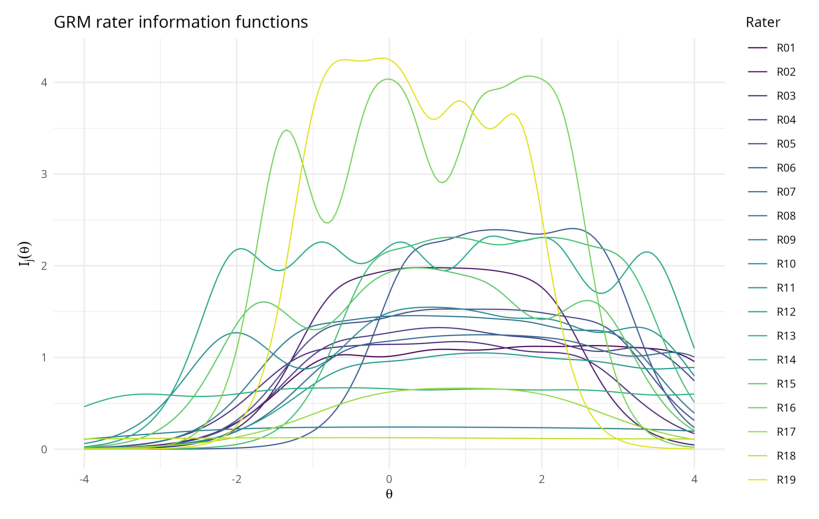

In [11]:
#| label: fig-grm-rater-information
#| fig-cap: "Rater information functions of the graded response model."
show_png("grm/figures/grm_rater_information.png")

**Information shares.** Each rater's share of the total information of all raters, along θ.

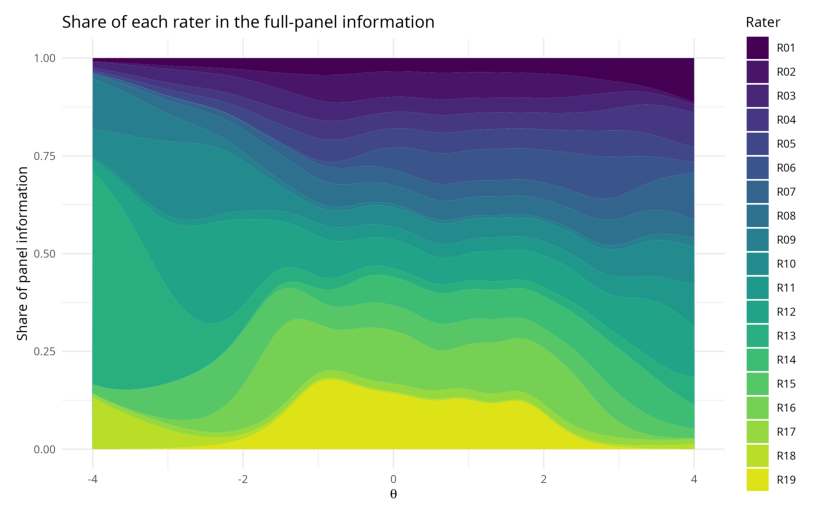

In [12]:
#| label: fig-grm-information-shares
#| fig-cap: "Share of each rater in the information of the full panel across the latent continuum."
show_png("grm/figures/grm_rater_information_shares.png")

**Information summary.** For each rater: information averaged over the N(0, 1) distribution of θ, where it peaks, and the rater's share of the full-panel information.

In [13]:
#| label: tbl-grm-information-summary
#| tbl-cap: "Rater information summary: information integrated over N(0, 1), location and height of the maximum, and share of the full-panel information (weighted over N(0, 1) and at selected theta)."
show_table("grm/rater_information_summary.csv")

| rater_id   |   n_ratings |   info_weighted_area |   theta_at_max |   info_max |   share_weighted |   share_at_theta_-2 |   share_at_theta_-1 |   share_at_theta_+0 |   share_at_theta_+1 |   share_at_theta_+2 |
|:-----------|------------:|---------------------:|---------------:|-----------:|-----------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| R01        |        1174 |                0.979 |          2.700 |      1.129 |            0.037 |               0.030 |               0.043 |               0.034 |               0.036 |               0.040 |
| R02        |         873 |                1.705 |          0.450 |      1.981 |            0.065 |               0.023 |               0.065 |               0.065 |               0.066 |               0.063 |
| R03        |         720 |                1.080 |          0.900 |      1.173 |            0.041 |               0.048 |               0.049 |               0.038 |               0.039 |               0.038 |
| R04        |         620 |                1.155 |          0.650 |      1.326 |            0.044 |               0.029 |               0.047 |               0.043 |               0.044 |               0.043 |
| R05        |         633 |                1.343 |          0.750 |      1.529 |            0.051 |               0.032 |               0.056 |               0.048 |               0.051 |               0.053 |
| R06        |         520 |                1.410 |          2.400 |      2.406 |            0.054 |               0.001 |               0.009 |               0.057 |               0.079 |               0.083 |
| R07        |         547 |                1.056 |          1.200 |      1.248 |            0.040 |               0.020 |               0.038 |               0.039 |               0.042 |               0.043 |
| R08        |         522 |                1.359 |          0.300 |      1.456 |            0.052 |               0.058 |               0.062 |               0.049 |               0.048 |               0.048 |
| R09        |         400 |                0.238 |          0.100 |      0.241 |            0.009 |               0.022 |               0.011 |               0.008 |               0.008 |               0.008 |
| R10        |         383 |                1.330 |          0.550 |      1.549 |            0.051 |               0.129 |               0.041 |               0.050 |               0.051 |               0.051 |
| R11        |         369 |                0.877 |          1.200 |      1.050 |            0.033 |               0.020 |               0.032 |               0.032 |               0.035 |               0.035 |
| R12        |         264 |                2.120 |          1.350 |      2.324 |            0.081 |               0.221 |               0.103 |               0.074 |               0.071 |               0.082 |
| R13        |         254 |                0.655 |         -0.550 |      0.669 |            0.025 |               0.061 |               0.031 |               0.022 |               0.022 |               0.023 |
| R14        |         259 |                1.722 |          0.800 |      2.311 |            0.066 |               0.005 |               0.031 |               0.072 |               0.077 |               0.082 |
| R15        |          73 |                1.710 |          0.350 |      1.978 |            0.065 |               0.138 |               0.060 |               0.065 |               0.063 |               0.050 |
| R16        |          52 |                3.300 |          1.850 |      4.069 |            0.126 |               0.111 |               0.126 |               0.135 |               0.116 |               0.143 |
| R17        |          52 |                0.543 |          0.950 |      0.665 |            0.021 |               0.013 |               0.018 |               0.021 |               0.022 |               0.021 |
| R18        |          55 |                0.123 |         -0.500 |      0.125 |            0.005 |               0.012 |               0.006 |               0.004 |               0.004 |               0.004 |
| R19        |          50 |                3.539 |         -0.100 |      4.266 |            0.135 |               0.026 |               0.171 |               0.142 |               0.126 |               0.090 |

**Full panel.** Information and conditional reliability I/(I+1) if every rater rated a product. This is a hypothetical upper bound, not the precision of the actual scores.

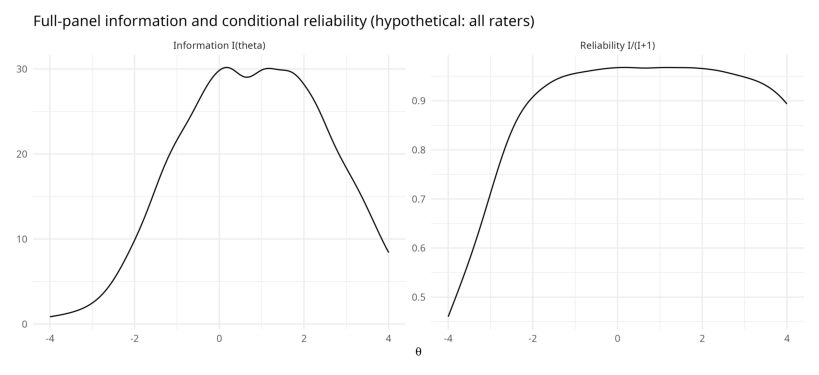

In [14]:
#| label: fig-grm-panel-information
#| fig-cap: "Information and conditional reliability I/(I+1) of the full panel. The curve is hypothetical: it applies to a product rated by all raters."
show_png("grm/figures/grm_panel_information_reliability.png")

**Reliability of the actual scores.** The empirical marginal reliability Var(θ̂)/(Var(θ̂) + mean PSD²) refers to the EAP scores actually obtained (Chalmers, 2012) and is the primary figure. The model-based marginal reliability (Green et al., 1984) refers to the hypothetical full panel. rel_post = 1 − PSD² gives each product's reliability from its own raters.

In [15]:
#| label: tbl-grm-reliability-summary
#| tbl-cap: "Reliability of the GRM scores: empirical marginal reliability of the actual EAP scores (primary), model-based marginal reliability of the hypothetical full panel, distribution of the product-level reliability rel_post = 1 - PSD^2, and its agreement with the information-based rel_info."
show_table("grm/reliability_summary.csv")

| quantity                                                        |   value |
|:----------------------------------------------------------------|--------:|
| empirical_marginal_reliability (primary; actual scores)         |   0.672 |
| model_based_marginal_reliability_mirt (hypothetical full panel) |   0.960 |
| model_based_marginal_reliability_grid (check)                   |   0.960 |
| var_theta_eap                                                   |   0.672 |
| mean_psd_squared                                                |   0.328 |
| rel_post_min                                                    |   0.057 |
| rel_post_p10                                                    |   0.485 |
| rel_post_q1                                                     |   0.596 |
| rel_post_median                                                 |   0.698 |
| rel_post_q3                                                     |   0.769 |
| rel_post_p90                                                    |   0.813 |
| rel_post_max                                                    |   0.929 |
| rel_post_mean                                                   |   0.672 |
| rel_post_iqr                                                    |   0.173 |
| consistency_cor_rel_post_rel_info                               |   0.935 |
| consistency_mean_diff_rel_info_minus_rel_post                   |   0.016 |
| consistency_max_abs_diff                                        |   0.413 |
| products_abs_diff_gt_0.1                                        | 320.000 |

**Reliability by number of ratings.** How product-level precision grows with the number of ratings a product received.

In [16]:
#| label: tbl-grm-reliability-by-n
#| tbl-cap: "Product-level reliability and posterior SD by number of ratings per product."
show_table("grm/reliability_by_n_ratings.csv")

|   n_ratings |   n_products |   rel_post_mean |   rel_post_median |   rel_info_mean |   psd_mean |
|------------:|-------------:|----------------:|------------------:|----------------:|-----------:|
|       1.000 |      897.000 |           0.520 |             0.553 |           0.544 |      0.686 |
|       2.000 |     2080.000 |           0.698 |             0.714 |           0.713 |      0.545 |
|       3.000 |      357.000 |           0.757 |             0.768 |           0.767 |      0.488 |
|       4.000 |      125.000 |           0.810 |             0.826 |           0.818 |      0.430 |
|       5.000 |      125.000 |           0.820 |             0.831 |           0.831 |      0.420 |
|       6.000 |       47.000 |           0.847 |             0.856 |           0.851 |      0.387 |
|       7.000 |       20.000 |           0.869 |             0.880 |           0.874 |      0.358 |
|       8.000 |       11.000 |           0.875 |             0.885 |           0.879 |      0.347 |
|       9.000 |        3.000 |           0.879 |             0.920 |           0.883 |      0.338 |
|      10.000 |        3.000 |           0.919 |             0.920 |           0.917 |      0.285 |

Distribution of product-level reliability across products.

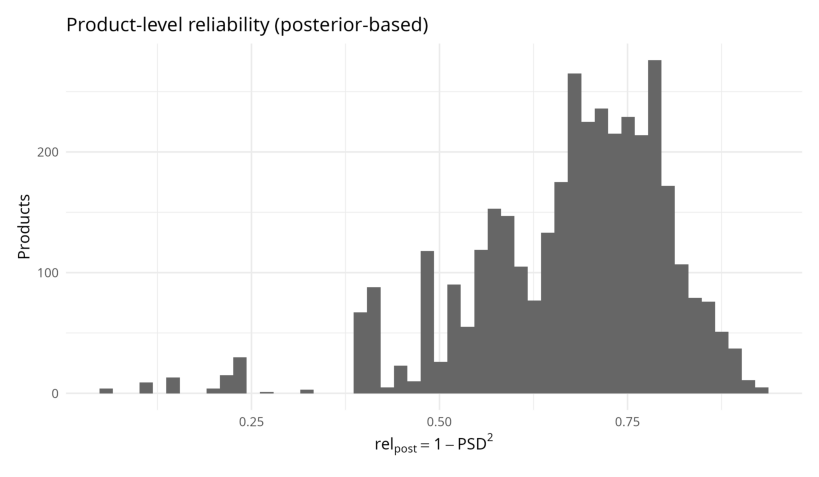

In [17]:
#| label: fig-grm-rel-post-histogram
#| fig-cap: "Distribution of the product-level reliability rel_post across all products."
show_png("grm/figures/grm_rel_post_histogram.png")

Product-level reliability by number of ratings (the same information as the table above, as a figure).

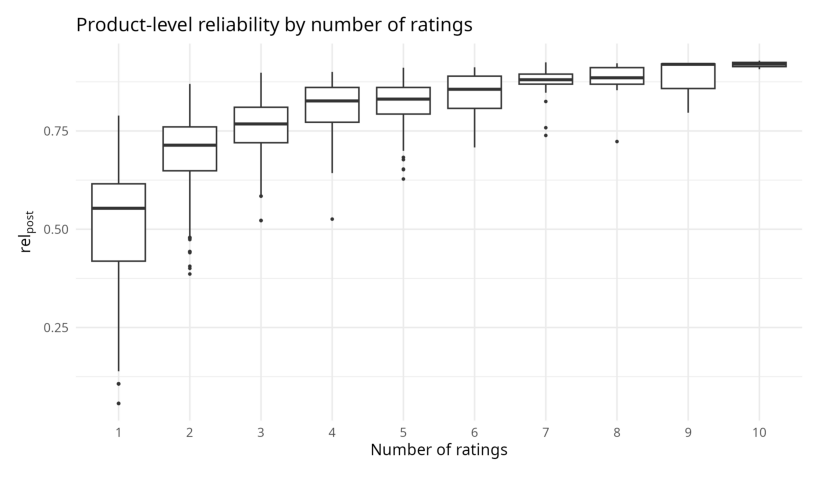

In [18]:
#| label: fig-grm-rel-post-by-n
#| fig-cap: "Product-level reliability rel_post by number of ratings per product."
show_png("grm/figures/grm_rel_post_by_n_ratings.png")

Product-level reliability by estimated creativity. Precision depends on where a product lies relative to its raters' thresholds.

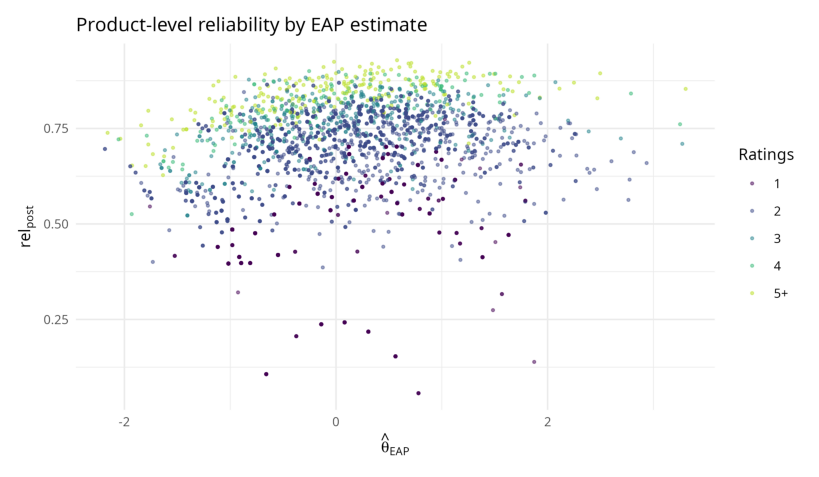

In [19]:
#| label: fig-grm-rel-post-by-theta
#| fig-cap: "Product-level reliability rel_post by EAP estimate."
show_png("grm/figures/grm_rel_post_by_theta.png")

**Check.** Two routes to the same product-level reliability: from the posterior (rel_post) and from the information of the product's own raters (rel_info). Points near the diagonal mean the two routes agree.

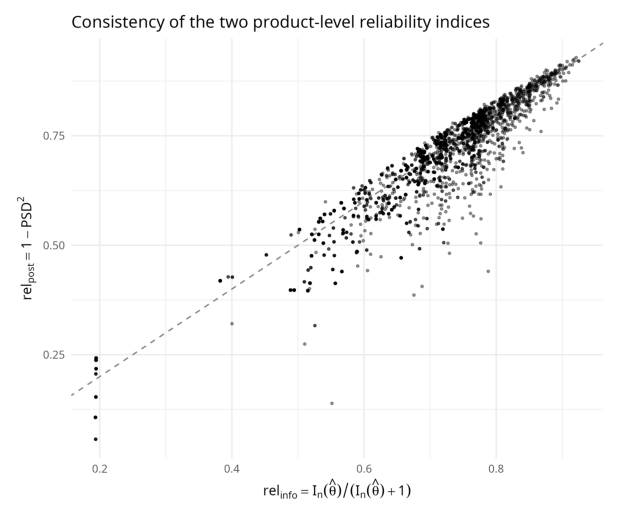

In [20]:
#| label: fig-grm-rel-consistency
#| fig-cap: "Agreement of the two product-level reliability indices: rel_info (information of the product's own raters at the EAP estimate) and rel_post (1 - PSD^2)."
show_png("grm/figures/grm_rel_consistency.png", width=6)

## 4. Comparison: model ladder and MFRM

**Model comparison.** The adjacent-category models form a ladder:
- M1, the rating scale model with a rater shift (Andrich, 1978). This is the many-facet Rasch model (Linacre, 1989; Primi et al., 2019), fitted with `sirt::rm.facets`.
- M2, the partial credit model (Masters, 1982): adds rater-specific thresholds.
- M3, the generalized partial credit model (Muraki, 1992): adds rater-specific discriminations.

The GRM belongs to the cumulative family, so it is compared with the ladder by information criteria only (lower is better).

In [21]:
#| label: tbl-model-fit
#| tbl-cap: "Fit of the adjacent-category ladder (M1 rating scale model / MFRM, M2 partial credit model, M3 generalized partial credit model) and the graded response model: log-likelihood, number of parameters and information criteria."
show_table("comparison/model_fit.csv", lambda d: d[d["status"] == "estimated"][["model", "software", "family", "logLik", "npar", "AIC", "BIC", "SABIC"]])

| model   | software        | family                        |     logLik |    npar |       AIC |       BIC |     SABIC |
|:--------|:----------------|:------------------------------|-----------:|--------:|----------:|----------:|----------:|
| M1_RSM  | sirt::rm.facets | adjacent category             | -12186.218 |  25.000 | 24422.435 | 24577.620 | 24498.183 |
| M2_PCM  | mirt            | adjacent category             | -11817.489 | 109.000 | 23852.978 | 24529.585 | 24183.237 |
| M3_GPCM | mirt            | adjacent category             | -11756.510 | 127.000 | 23767.020 | 24555.360 | 24151.817 |
| GRM     | mirt            | cumulative (not in LR ladder) | -11733.227 | 127.000 | 23720.455 | 24508.795 | 24105.251 |

**Likelihood-ratio tests.** Each test checks whether the next step up the ladder improves fit: rater-specific thresholds (M1 vs M2), then rater-specific discriminations (M2 vs M3).

In [22]:
#| label: tbl-lr-tests
#| tbl-cap: "Likelihood-ratio tests within the adjacent-category ladder."
show_table("comparison/lr_tests.csv", lambda d: d[["comparison", "X2", "df", "df_expected_formula", "p"]])

| comparison                               |      X2 |   df |   df_expected_formula |     p |
|:-----------------------------------------|--------:|-----:|----------------------:|------:|
| M1 vs M2: rater-specific thresholds      | 737.457 |   84 |                    90 | 0.000 |
| M2 vs M3: rater-specific discriminations | 121.958 |   18 |                    18 | 0.000 |

**Agreement of scores.** Correlations of the product scores between models. High values mean the ranking of products hardly depends on the model.

In [23]:
#| label: tbl-theta-correlations
#| tbl-cap: "Correlations of the EAP estimates between models (Pearson and Spearman)."
show_table("comparison/theta_correlations.csv")

| method   | model                  |   M1_RSM |   M2_PCM |   M3_GPCM |   GRM |   rm_facets_default_grid |
|:---------|:-----------------------|---------:|---------:|----------:|------:|-------------------------:|
| pearson  | M1_RSM                 |    1.000 |    0.993 |     0.980 | 0.975 |                    1.000 |
| pearson  | M2_PCM                 |    0.993 |    1.000 |     0.989 | 0.985 |                    0.993 |
| pearson  | M3_GPCM                |    0.980 |    0.989 |     1.000 | 0.996 |                    0.980 |
| pearson  | GRM                    |    0.975 |    0.985 |     0.996 | 1.000 |                    0.975 |
| pearson  | rm_facets_default_grid |    1.000 |    0.993 |     0.980 | 0.975 |                    1.000 |
| spearman | M1_RSM                 |    1.000 |    0.996 |     0.983 | 0.978 |                    1.000 |
| spearman | M2_PCM                 |    0.996 |    1.000 |     0.987 | 0.983 |                    0.996 |
| spearman | M3_GPCM                |    0.983 |    0.987 |     1.000 | 0.996 |                    0.983 |
| spearman | GRM                    |    0.978 |    0.983 |     0.996 | 1.000 |                    0.978 |
| spearman | rm_facets_default_grid |    1.000 |    0.996 |     0.983 | 0.978 |                    1.000 |

Rater discriminations in M3. Their spread shows how far the equal-discrimination assumption of M1 and M2 is from the data.

In [24]:
#| label: tbl-discrimination-m3
#| tbl-cap: "Rater discriminations in the generalized partial credit model (M3)."
show_table("comparison/discrimination_m3.csv", lambda d: d[["rater_id", "n_ratings", "estimate", "se"]])

| rater_id   |   n_ratings |   estimate |    se |
|:-----------|------------:|-----------:|------:|
| R09        |         400 |      0.283 | 0.055 |
| R18        |          55 |      0.312 | 0.145 |
| R17        |          52 |      0.616 | 0.235 |
| R13        |         254 |      0.863 | 0.159 |
| R11        |         369 |      0.896 | 0.145 |
| R03        |         720 |      0.984 | 0.142 |
| R04        |         620 |      0.992 | 0.184 |
| R07        |         547 |      1.025 | 0.138 |
| R05        |         633 |      1.096 | 0.154 |
| R08        |         522 |      1.102 | 0.195 |
| R02        |         873 |      1.209 | 0.272 |
| R01        |        1174 |      1.304 | 0.131 |
| R10        |         383 |      1.370 | 0.320 |
| R15        |          73 |      1.389 | 0.412 |
| R14        |         259 |      1.390 | 0.433 |
| R06        |         520 |      1.942 | 0.385 |
| R19        |          50 |      2.327 | 1.866 |
| R12        |         264 |      2.383 | 0.680 |
| R16        |          52 |      2.606 | 1.419 |

Raters whose adjacent-category step parameters are out of order. In adjacent-category models this means that some category is never the most likely response (Andrich, 1978). In the GRM, thresholds are ordered by construction.

In [25]:
#| label: tbl-threshold-order
#| tbl-cap: "Raters with unordered step parameters in M2 (PCM) and M3 (GPCM)."
show_table("comparison/threshold_order.csv", lambda d: d[~d["ordered"]])

| model   | rater_id   |   n_steps | ordered   |   n_reversals | steps                            |
|:--------|:-----------|----------:|:----------|--------------:|:---------------------------------|
| M2_PCM  | R03        |         5 | False     |             1 | -0.87;-0.21;1.11;0.69;2.64       |
| M2_PCM  | R04        |         6 | False     |             1 | -0.54;0.58;0.68;0.52;2.18;3.77   |
| M2_PCM  | R05        |         6 | False     |             1 | -0.74;0.62;0.58;1.46;1.81;2.72   |
| M2_PCM  | R06        |         5 | False     |             1 | 0.92;1.26;1.60;2.85;2.38         |
| M2_PCM  | R11        |         6 | False     |             1 | -0.36;0.96;1.06;0.93;2.65;4.15   |
| M2_PCM  | R15        |         6 | False     |             2 | -2.18;0.35;0.35;0.15;1.29;3.12   |
| M2_PCM  | R16        |         6 | False     |             1 | -2.09;0.18;-0.19;1.81;1.87;1.99  |
| M2_PCM  | R17        |         4 | False     |             2 | 0.49;0.18;1.30;0.98              |
| M2_PCM  | R19        |         6 | False     |             2 | -0.43;-0.85;0.10;-0.29;1.21;1.76 |
| M3_GPCM | R03        |         5 | False     |             1 | -0.82;-0.19;1.11;0.65;2.59       |
| M3_GPCM | R04        |         6 | False     |             1 | -0.53;0.58;0.66;0.48;2.13;3.69   |
| M3_GPCM | R05        |         6 | False     |             1 | -0.69;0.57;0.56;1.38;1.72;2.57   |
| M3_GPCM | R06        |         5 | False     |             1 | 0.51;1.06;1.46;2.30;2.27         |
| M3_GPCM | R09        |         6 | False     |             2 | -0.43;-0.78;0.63;-0.12;1.10;3.92 |
| M3_GPCM | R11        |         6 | False     |             1 | -0.29;1.09;1.14;0.94;2.78;4.31   |
| M3_GPCM | R15        |         6 | False     |             1 | -1.90;0.21;0.34;0.28;1.20;2.81   |
| M3_GPCM | R17        |         4 | False     |             2 | 1.12;0.22;1.74;0.83              |
| M3_GPCM | R18        |         5 | False     |             1 | -7.29;-2.14;0.42;-0.70;5.02      |

Infit and outfit under M1, the fit statistics usually reported for many-facet Rasch models (Eckes, 2015).

In [26]:
#| label: tbl-rater-fit-m1
#| tbl-cap: "Rater infit and outfit mean squares under M1 (rating scale model / MFRM)."
show_table("comparison/rater_fit_m1.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit"]])

| rater_id   |   n_ratings |   infit |   outfit |
|:-----------|------------:|--------:|---------:|
| R01        |        1174 |   0.466 |    0.481 |
| R02        |         873 |   0.786 |    0.782 |
| R03        |         720 |   0.579 |    0.579 |
| R04        |         620 |   0.687 |    0.660 |
| R05        |         633 |   0.701 |    0.669 |
| R06        |         520 |   0.909 |    0.705 |
| R07        |         547 |   0.826 |    0.751 |
| R08        |         522 |   0.540 |    0.548 |
| R09        |         400 |   0.978 |    0.958 |
| R10        |         383 |   0.407 |    0.389 |
| R11        |         369 |   0.938 |    0.874 |
| R12        |         264 |   0.238 |    0.255 |
| R13        |         254 |   0.405 |    0.406 |
| R14        |         259 |   0.747 |    0.695 |
| R15        |          73 |   0.753 |    0.698 |
| R16        |          52 |   0.452 |    0.457 |
| R17        |          52 |   1.328 |    1.190 |
| R18        |          55 |   1.009 |    1.071 |
| R19        |          50 |   0.654 |    0.701 |

Marginal reliability (hypothetical full panel) and empirical reliability (actual scores) for each model.

In [27]:
#| label: tbl-marginal-reliability-models
#| tbl-cap: "Marginal and empirical reliability by model, for comparison."
show_table("comparison/marginal_reliability.csv")

| model   |   latent_variance |   marginal_reliability |   marginal_rxx_mirt |   empirical_rxx |
|:--------|------------------:|-----------------------:|--------------------:|----------------:|
| M1_RSM  |             0.962 |                  0.943 |             nan     |           0.626 |
| M2_PCM  |             1.087 |                  0.944 |             nan     |           0.637 |
| M3_GPCM |             1.000 |                  0.955 |               0.955 |           0.657 |
| GRM     |             1.000 |                  0.960 |               0.960 |           0.672 |

## 5. Naive indices and overview

**Naive indices** are reference values for common practice. They are not used downstream.
- **Cronbach's α** (Cronbach, 1951) measures the consistency of the unweighted rater mean. It assumes τ-equivalent raters and complete data, so here it is computed from pairwise covariances and on the largest fully crossed block.
- **Krippendorff's α** (ordinal; Hayes & Krippendorff, 2007) measures the agreement of single ratings, treating raters as interchangeable. Its confidence interval comes from a bootstrap over products.

In [28]:
def naive_indices():
    cr, ka = read_res("naive/cronbach_alpha.csv"), read_res("naive/krippendorff_alpha.csv")
    if cr is None or ka is None:
        return None
    return pd.concat([
        pd.DataFrame({"index": "Cronbach's alpha: " + cr["variant"], "value": cr["raw_alpha"],
                      "ci_low": None, "ci_high": None, "n_raters": cr["n_raters"],
                      "n_products": cr["n_products_contributing"]}),
        pd.DataFrame({"index": "Krippendorff's alpha (ordinal)", "value": ka["alpha"],
                      "ci_low": ka["ci_low"], "ci_high": ka["ci_high"], "n_raters": ka["n_raters"],
                      "n_products": ka["n_pairable_units"]}),
    ], ignore_index=True)

In [29]:
#| label: tbl-naive-indices
#| tbl-cap: "Cronbach's alpha (consistency of the unweighted rater mean) and Krippendorff's alpha (ordinal agreement of single ratings, 95% bootstrap CI over products)."
_naive = naive_indices()
_missing("naive/*.csv") if _naive is None else Markdown(_naive.to_markdown(index=False, floatfmt=".3f"))

| index                                                     |   value |   ci_low |   ci_high |   n_raters |   n_products |
|:----------------------------------------------------------|--------:|---------:|----------:|-----------:|-------------:|
| Cronbach's alpha: pairwise covariances, all usable raters |   0.928 |          |           |         14 |         1900 |
| Cronbach's alpha: fully crossed block (listwise complete) |   0.658 |          |           |          3 |          139 |
| Krippendorff's alpha (ordinal)                            |   0.392 |    0.362 |     0.417 |         19 |         2771 |

**Overview.** All indices side by side, with what each refers to. They answer different questions: the reliability of the actual scores, of a hypothetical full panel, or of single ratings. They are not interchangeable.

In [30]:
#| label: tbl-reliability-overview
#| tbl-cap: "Overview of the reliability and agreement indices and what each refers to."
show_table("summary/reliability_overview.csv")

| index                                   | refers_to                                                 |   value | ci_or_note                                         |
|:----------------------------------------|:----------------------------------------------------------|--------:|:---------------------------------------------------|
| Krippendorff's alpha (ordinal)          | consensus of single ratings                               |   0.392 | 95% bootstrap CI [0.362, 0.417], 1000 replications |
| Cronbach's alpha (pairwise covariances) | consistency of the unweighted rater mean                  |   0.928 | 14 raters; removed: R19;R14;R02;R16;R12            |
| Cronbach's alpha (fully crossed block)  | consistency of the unweighted rater mean (crossed subset) |   0.658 | 3 raters, 139 products                             |
| GRM: empirical marginal reliability     | actual theta_hat (primary)                                |   0.672 | Var(theta)/(Var(theta)+mean(PSD^2))                |
| GRM: model-based marginal reliability   | hypothetical full panel                                   |   0.960 | mirt::marginal_rxx, all raters                     |
| GRM: median rel_post                    | precision per product                                     |   0.698 | Q1 0.596, Q3 0.769                                 |
| GRM: IQR rel_post                       | precision per product                                     |   0.173 | nan                                                |
| M1 (RSM): marginal reliability          | comparison                                                |   0.943 | nan                                                |
| M2 (PCM): marginal reliability          | comparison                                                |   0.944 | nan                                                |
| M3 (GPCM): marginal reliability         | comparison                                                |   0.955 | nan                                                |

## References

- Andrich, D. (1978). A rating formulation for ordered response categories. *Psychometrika, 43*(4), 561–573.
- Cai, L., & Monroe, S. (2014). *A new statistic for evaluating item response theory models for ordinal data* (CRESST Report 839). University of California, Los Angeles.
- Chalmers, R. P. (2012). mirt: A multidimensional item response theory package for the R environment. *Journal of Statistical Software, 48*(6), 1–29.
- Christensen, K. B., Makransky, G., & Horton, M. (2017). Critical values for Yen's Q3: Identification of local dependence in the Rasch model using residual correlations. *Applied Psychological Measurement, 41*(3), 178–194.
- Cronbach, L. J. (1951). Coefficient alpha and the internal structure of tests. *Psychometrika, 16*(3), 297–334.
- Eckes, T. (2015). *Introduction to many-facet Rasch measurement* (2nd ed.). Peter Lang.
- Green, B. F., Bock, R. D., Humphreys, L. G., Linn, R. L., & Reckase, M. D. (1984). Technical guidelines for assessing computerized adaptive tests. *Journal of Educational Measurement, 21*(4), 347–360.
- Hayes, A. F., & Krippendorff, K. (2007). Answering the call for a standard reliability measure for coding data. *Communication Methods and Measures, 1*(1), 77–89.
- Kang, T., & Chen, T. T. (2008). Performance of the generalized S-X² item fit index for polytomous IRT models. *Journal of Educational Measurement, 45*(4), 391–406.
- Linacre, J. M. (1989). *Many-facet Rasch measurement*. MESA Press.
- Masters, G. N. (1982). A Rasch model for partial credit scoring. *Psychometrika, 47*(2), 149–174.
- Muraki, E. (1992). A generalized partial credit model: Application of an EM algorithm. *Applied Psychological Measurement, 16*(2), 159–176.
- Myszkowski, N., & Storme, M. (2019). Judge response theory? A call to upgrade our psychometrical account of creativity judgments. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 167–175.
- Orlando, M., & Thissen, D. (2000). Likelihood-based item-fit indices for dichotomous item response theory models. *Applied Psychological Measurement, 24*(1), 50–64.
- Primi, R., Silvia, P. J., Jauk, E., & Benedek, M. (2019). Applying many-facet Rasch modeling in the assessment of creativity. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 176–186.
- Samejima, F. (1969). Estimation of latent ability using a response pattern of graded scores. *Psychometrika Monograph Supplement*, No. 17.
- Wright, B. D., & Masters, G. N. (1982). *Rating scale analysis*. MESA Press.
- Yen, W. M. (1984). Effects of local item dependence on the fit and equating performance of the three-parameter logistic model. *Applied Psychological Measurement, 8*(2), 125–145.